# Digbodha 1: Text-Prompted Motion and Collision-Risk Estimation from a Single Camera

**K Praveen Sagar (CS26M1002), Arnav Abhijit Rajurkar (CS26M1007), Madhur Vijay Patil (CS26M1024)** · M.Tech CSE (Data Science & AI), IIITDM Kancheepuram · Computer Vision course project
Code: https://github.com/spi727/digbodha · Base paper: *SAM 3: Segment Anything with Concepts* (Carion et al., arXiv:2511.16719, 2025)

Given a video and object names ("vehicle, person"), the pipeline outputs, per object and per frame: its motion with the camera's own motion removed, its **time to contact (TTC)**, whether it is on a **collision course**, and a risk label (safe / caution / danger / uncertain). No depth sensor or calibration is used.

| Stage | Type | File |
|---|---|---|
| 1. Segment + track named objects (SAM 3.1, chunked for 8 GB GPU) | deep learning | `src/segment.py` |
| 2. Camera-motion removal (Shi–Tomasi + Lucas–Kanade + RANSAC homography) | classical CV | `src/egomotion.py` |
| 3. TTC from looming (1/size line fit, Lee's tau) + collision course + risk | classical CV | `src/ttc.py` |
| Evaluation against KITTI 3D labels | | `eval/` |

## How to run (Google Colab)

**Runtime → Run all.** Two modes, set in the next cell:

- **`MODE = "results"`** (default): no GPU and no login needed, about 1–2 minutes. Downloads a small results pack (KITTI sequence 0007 frames + the saved SAM 3.1 output for it + saved evaluations), re-runs the classical stages and the evaluation, and shows the annotated video.
- **`MODE = "full"`**: runs the whole pipeline including SAM 3.1. Needs **Runtime → Change runtime type → GPU** and a Hugging Face token with access to `facebook/sam3.1` (the cell asks for it). Then section 7 lets you **upload your own video** and get the annotated video + `labels.json`.

## 1. Setup

In [1]:
MODE = "results"          # "results" (no GPU, ~1-2 min)  or  "full" (GPU + Hugging Face token)

REPO_URL = "https://github.com/spi727/digbodha"
PACK_URL = REPO_URL + "/releases/download/v1.0/digbodha_results_pack.zip"
SEQ, N, FPS = "0007", 300, 10   # KITTI held-out sequence used for the demo

import os, sys, subprocess, zipfile, urllib.request
IN_COLAB = "google.colab" in sys.modules

# 1. get the code (in Colab: clone the repo; locally: run from the repo root)
if not os.path.exists("analyze.py"):
    if not os.path.exists("digbodha"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    os.chdir("digbodha")
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imageio", "imageio-ffmpeg", "scipy", "matplotlib"], check=True)

# 2. get the results pack (KITTI 0007 frames, its labels, saved SAM output, saved evaluations)
FRAMES = f"data/kitti_{SEQ}_{N}"
if not (os.path.isdir(FRAMES) and os.path.exists(f"outputs/kitti_{SEQ}/frames.csv")):
    print("downloading the results pack ...")
    urllib.request.urlretrieve(PACK_URL, "pack.zip")
    zipfile.ZipFile("pack.zip").extractall(".")
    os.remove("pack.zip")
local_labels = os.path.expanduser(f"~/datasets/kitti_tracking/training/label_02/{SEQ}.txt")
LABELS = local_labels if os.path.exists(local_labels) else f"kitti_labels/{SEQ}.txt"
OUT = f"outputs/nb_kitti_{SEQ}"
os.makedirs(OUT, exist_ok=True)
print("repo:", os.getcwd(), "| mode:", MODE, "| Colab:", IN_COLAB)

repo: /home/prave/projects/digbodha | mode: results | Colab: False


In [2]:
import csv, glob, json
from collections import Counter
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import Video, display

from src.ttc import TTCEstimator
from src.labels import build_labels, extract_frames, num
from src.visualize import write_video, draw, load_rows, list_frames

def run(cmd):
    """Run a repo script, show its output, stop on error."""
    p = subprocess.run([sys.executable] + cmd, capture_output=True, text=True)
    print(p.stdout[-6000:])
    if p.returncode:
        print(p.stderr[-4000:])
        raise RuntimeError("command failed: " + " ".join(cmd))

print("frames:", len(glob.glob(FRAMES + "/*.jpg")), "| labels:", LABELS)

frames: 300 | labels: /home/prave/datasets/kitti_tracking/training/label_02/0007.txt


### Full mode only: install SAM 3.1

Skipped in results mode. In full mode: checks for a GPU, installs SAM 3 from GitHub, and logs in to Hugging Face (paste a token from https://huggingface.co/settings/tokens; the account must have been granted access to `facebook/sam3.1`).

In [3]:
if MODE == "full":
    import torch
    assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> GPU, then run all again"
    print("GPU:", torch.cuda.get_device_name(0))
    try:
        import sam3  # noqa: F401
        print("SAM 3 already installed")
    except ImportError:
        if not os.path.exists("../sam3"):
            subprocess.run(["git", "clone", "--depth", "1", "https://github.com/facebookresearch/sam3", "../sam3"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "../sam3"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "setuptools<81", "pycocotools",
                        "scikit-image", "scikit-learn", "einops", "huggingface_hub"], check=True)
        sys.path.insert(0, os.path.abspath("../sam3"))
    from huggingface_hub import login
    token = os.environ.get("HF_TOKEN")
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")      # Colab secret named HF_TOKEN, if you added one
        except Exception:
            token = None
    if not token:
        from getpass import getpass
        token = getpass("Hugging Face token: ")
    login(token=token)
else:
    print("results mode: SAM 3.1 not needed")

results mode: SAM 3.1 not needed


## 2. The principle: time to contact from looming

For an object of real height $H$ at depth $Z$, its image height is $s = fH/Z$. If it closes at constant speed $v$, then
$$\frac{1}{s} = \frac{Z}{fH} = \frac{Z_0 - v t}{fH},$$
which is a **straight line in time that reaches zero at the moment of contact**. Fitting a line to $1/s$ over the last 0.8 s and taking its zero crossing gives TTC with no lag and without knowing $f$, $H$ or $Z$ (Lee, 1976).

The lateral offset in object heights, $q = x/s$, is extrapolated to contact: miss $m = q + \dot q \cdot \mathrm{TTC}$. $|m| < 1$ means on a collision course.

Below, two synthetic objects approach a camera at 10 m/s: one head-on, one passing 4 m to the side.

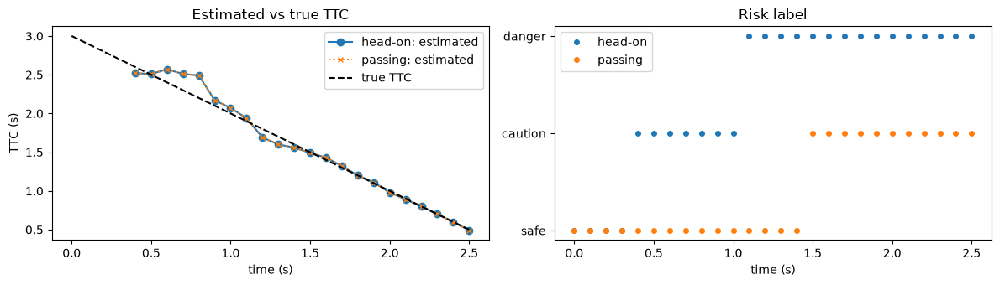

head-on  t=2.5s  true TTC 0.50s  estimated 0.49s  miss +0.20 heights  -> danger
passing  t=2.5s  true TTC 0.50s  estimated 0.49s  miss +2.65 heights  -> caution


In [4]:
f, H, v, Z0 = 700.0, 1.5, 10.0, 30.0       # focal (px), object height (m), closing speed (m/s), start depth (m)
W_IMG, H_IMG = 1242, 375
objs = {1: ("head-on", 0.3), 2: ("passing", 4.0)}   # lateral offset X (m)
est = TTCEstimator(fps=FPS)
log = {k: [] for k in objs}
for i in range(26):                          # 2.5 s
    t = i / FPS
    Z = Z0 - v * t
    items = []
    for oid, (name, X) in objs.items():
        s, xc = f * H / Z, W_IMG / 2 + f * X / Z
        items.append({"id": oid, "label": "vehicle", "raw_flow": None, "own_flow": None,
                      "box": (int(xc - 0.4 * s), int(200 - s / 2), int(xc + 0.4 * s), int(200 + s / 2))})
    res = est.update_boxes(i, items, W_IMG, H_IMG)
    for oid in objs:
        log[oid].append((t, Z / v, res[oid]["ttc_s"], res[oid]["risk"], res[oid]["miss_widths"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for oid, (name, X) in objs.items():
    t, true, ttc, risk, miss = zip(*log[oid])
    ax[0].plot(t, [x if x is not None and x < 20 else np.nan for x in ttc], "o-" if oid == 1 else "x:",
               ms=6 if oid == 1 else 5, label=f"{name}: estimated")
ax[0].plot(t, true, "k--", label="true TTC")
ax[0].set(xlabel="time (s)", ylabel="TTC (s)", title="Estimated vs true TTC"); ax[0].legend()
for oid, (name, X) in objs.items():
    ax[1].plot([r[0] for r in log[oid]], [r[3] for r in log[oid]], "o", ms=4, label=name)
ax[1].set(xlabel="time (s)", title="Risk label"); ax[1].legend()
plt.tight_layout(); plt.show()
for oid, (name, X) in objs.items():
    t, true, ttc, risk, miss = log[oid][-1]
    print(f"{name:8s} t={t:.1f}s  true TTC {true:.2f}s  estimated {ttc:.2f}s  miss {miss:+.2f} heights  -> {risk}")

## 3. Run the pipeline on KITTI sequence 0007 (held out)

- **results mode:** stage 1 (SAM 3.1) and the ego-motion measurements are loaded from the saved run; stage 3 (TTC, collision course, risk) is re-run now with `eval/rescore.py`.
- **full mode:** all three stages run now with `analyze.py` (about 3–6 minutes for 300 frames on a T4).

In [5]:
if MODE == "full":
    run(["analyze.py", "--video", FRAMES, "--fps", str(FPS), "--prompts", "vehicle,person", "--out", OUT, "--no_video"])
else:
    run(["eval/rescore.py", "--pred", f"outputs/kitti_{SEQ}/frames.csv", "--frames", FRAMES,
         "--fps", str(FPS), "--out", f"{OUT}/frames.csv"])
PRED = f"{OUT}/frames.csv"
rows = list(csv.DictReader(open(PRED)))
print(len(rows), "object-frames,", len({r['id'] for r in rows}), "tracked objects")
print("risk labels:", dict(Counter(r["risk"] for r in rows)))

re-scored 1640 object-frames (289 frames, image 1242x375) -> outputs/nb_kitti_0007/frames.csv

1640 object-frames, 36 tracked objects
risk labels: {'safe': 1248, 'caution': 234, 'danger': 22, 'uncertain': 136}


## 4. What the output looks like

The three frames with the most caution/danger objects (green safe, amber caution, red danger, purple uncertain).

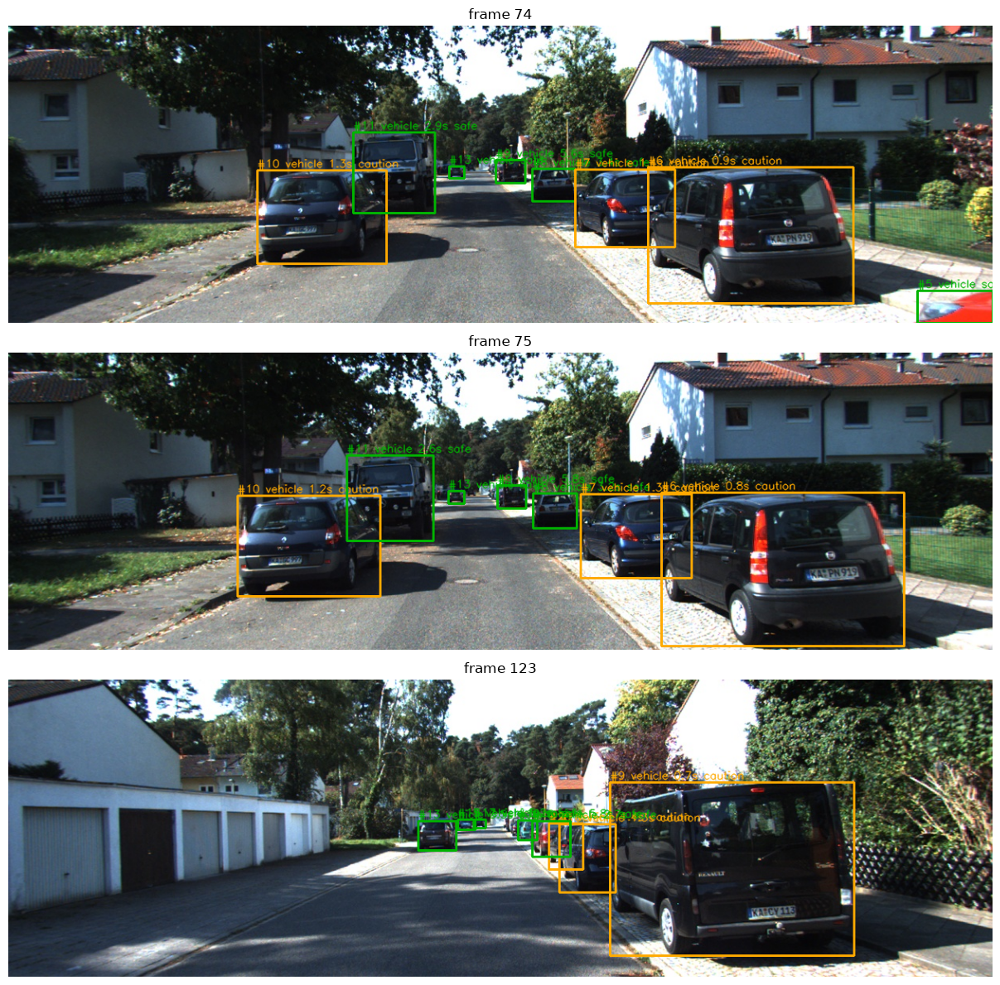

In [6]:
by_frame = load_rows(PRED)
paths = list_frames(FRAMES)
score = {fr: sum(r["risk"] in ("caution", "danger") for r in rs) for fr, rs in by_frame.items()}
show = sorted(sorted(score, key=score.get, reverse=True)[:3])
fig, axes = plt.subplots(len(show), 1, figsize=(14, 4 * len(show)))
for ax, fr in zip(np.atleast_1d(axes), show):
    ax.imshow(draw(paths[fr], by_frame.get(fr, []))); ax.set_title(f"frame {fr}"); ax.axis("off")
plt.tight_layout(); plt.show()

### The original input video (no annotations)

The KITTI frames exactly as the pipeline receives them, at real-time speed (10 FPS).

In [7]:
import imageio.v2 as imageio
ORIG = f"{OUT}/original_{SEQ}.mp4"
w = imageio.get_writer(ORIG, format="FFMPEG", fps=FPS, codec="libx264", quality=5,
                       macro_block_size=8, ffmpeg_log_level="error")
for p in list_frames(FRAMES):
    img = cv2.imread(p)[:, :, ::-1]
    w.append_data(cv2.resize(img, (960, 288), interpolation=cv2.INTER_AREA))   # 960x288: multiples of 8
w.close()
print(f"{ORIG}: {len(list_frames(FRAMES))} frames, {len(list_frames(FRAMES)) / FPS:.0f} s, {os.path.getsize(ORIG) / 1e6:.1f} MB")
display(Video(ORIG, embed=True, width=960))

outputs/nb_kitti_0007/original_0007.mp4: 300 frames, 30 s, 4.9 MB


### The whole sequence as a video, at 0.25× speed

In [8]:
SPEED = 0.25
VIDEO = write_video(FRAMES, PRED, f"{OUT}/annotated_{SPEED:g}x.mp4", FPS, speed=SPEED)
print(f"{VIDEO}: {len(paths) / (FPS * SPEED):.0f} s, {os.path.getsize(VIDEO) / 1e6:.1f} MB")
display(Video(VIDEO, embed=True, width=960))

outputs/nb_kitti_0007/annotated_0.25x.mp4: 120 s, 10.1 MB


## 5. Evaluation against KITTI ground truth

KITTI has no TTC labels, so they are derived from its 3D boxes: true TTC = $Z / (-\dot Z)$ (line fit over ±4 frames), true miss = lateral position at contact / object height. Predictions are matched to labels by box IoU ≥ 0.5.


=== KITTI evaluation: 289 frames, 1090 GT objects within 40 m, 90.5% matched ===

Time to contact (objects approaching in truth and in our estimate):
  ttc_all          {'n': 849, 'median_abs_s': 0.25, 'mean_abs_s': 0.61, 'median_rel_pct': 14.6, 'within_20pct': 67.4}
  ttc_reliable     {'n': 681, 'median_abs_s': 0.22, 'mean_abs_s': 0.42, 'median_rel_pct': 12.3, 'within_20pct': 78.9}
  ttc_unreliable   {'n': 168, 'median_abs_s': 0.55, 'mean_abs_s': 1.41, 'median_rel_pct': 69.5, 'within_20pct': 20.8}
  reliable, by true depth:
    0-10 m   {'n': 103, 'median_abs_s': 0.19, 'mean_abs_s': 0.31, 'median_rel_pct': 17.4, 'within_20pct': 68.9}
    10-20 m  {'n': 286, 'median_abs_s': 0.19, 'mean_abs_s': 0.3, 'median_rel_pct': 12.0, 'within_20pct': 83.9}
    20-40 m  {'n': 292, 'median_abs_s': 0.32, 'mean_abs_s': 0.57, 'median_rel_pct': 10.2, 'within_20pct': 77.4}

Approach detection: {'tp': 849, 'fp': 5, 'fn': 74, 'precision': 0.994, 'recall': 0.92}

Risk (rows = truth, columns = ours):
       

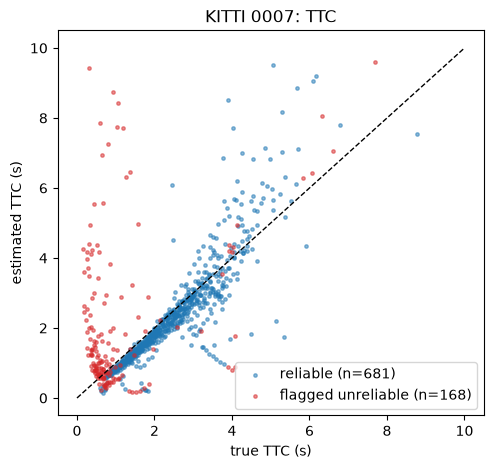

In [9]:
EVAL = f"{OUT}/eval"
run(["eval/evaluate_kitti.py", "--pred", PRED, "--labels", LABELS, "--fps", str(FPS), "--out", EVAL])

m = list(csv.DictReader(open(f"{EVAL}/matched.csv")))
pts = [(num(r["gt_ttc"]), num(r["pred_ttc"]), r["reliable"] in ("True", "true", "1"))
       for r in m if num(r["gt_ttc"]) is not None and num(r["pred_ttc"]) is not None]
pts = [p for p in pts if p[0] < 10 and p[1] < 10]
plt.figure(figsize=(5.5, 5))
for rel, c, lab in ((True, "tab:blue", "reliable"), (False, "tab:red", "flagged unreliable")):
    g = [(a, b) for a, b, r in pts if r == rel]
    if g:
        plt.scatter(*zip(*g), s=6, alpha=0.5, c=c, label=f"{lab} (n={len(g)})")
plt.plot([0, 10], [0, 10], "k--", lw=1)
plt.xlabel("true TTC (s)"); plt.ylabel("estimated TTC (s)"); plt.title(f"KITTI {SEQ}: TTC"); plt.legend()
plt.show()

## 6. All sequences: tuning set and held-out set

Pools the saved evaluations of the tuning sequences (0013, 0001, 0020) and the held-out sequences (0019, 0007): TTC accuracy, alert precision/recall, error attribution and event-level warnings.

In [10]:
for name, tag, seqs in (("TUNING", "v5_nodebounce", ["0013", "0001", "0020"]),
                        ("HELD-OUT", "heldout_nodebounce", ["0019", "0007"])):
    dirs = [f"outputs/eval_{s}_{tag}" for s in seqs if os.path.exists(f"outputs/eval_{s}_{tag}/matched.csv")]
    if not dirs:
        print(f"{name}: no saved evaluations found ({tag})"); continue
    print("#" * 30, name, "#" * 30)
    run(["eval/aggregate.py", *dirs, "--out", f"outputs/eval_pooled_{tag}"])
    run(["eval/analyze_errors.py", *dirs])

############################## TUNING ##############################



=== Pooled over eval_0013_v5_nodebounce, eval_0001_v5_nodebounce, eval_0020_v5_nodebounce: 4739 matched object-frames ===
TTC all       : {'n': 3428, 'median_abs_s': 0.3, 'median_rel_pct': 14.7, 'within_20pct': 63.3}
TTC reliable  : {'n': 2791, 'median_abs_s': 0.27, 'median_rel_pct': 12.9, 'within_20pct': 70.9}
   0-10 m    {'n': 352, 'median_abs_s': 0.14, 'median_rel_pct': 12.3, 'within_20pct': 74.1}
   10-20 m   {'n': 1375, 'median_abs_s': 0.24, 'median_rel_pct': 12.0, 'within_20pct': 76.1}
   20-40 m   {'n': 1064, 'median_abs_s': 0.49, 'median_rel_pct': 14.5, 'within_20pct': 63.3}
Approach      : {'tp': 3428, 'fp': 125, 'fn': 425, 'precision': 0.965, 'recall': 0.89}
Risk (rows = truth, cols = ours):
                  safe uncertain   caution    danger
  safe            3196       122       302        23
  caution          201       256       601        24
  danger             8         1         3         2
Alerts        : {'tp': 630, 'fp': 325, 'fn': 466, 'fn_flagged_uncertain': 2


=== Pooled over eval_0019_heldout_nodebounce, eval_0007_heldout_nodebounce: 2408 matched object-frames ===
TTC all       : {'n': 1735, 'median_abs_s': 0.33, 'median_rel_pct': 13.6, 'within_20pct': 66.3}
TTC reliable  : {'n': 1427, 'median_abs_s': 0.28, 'median_rel_pct': 11.5, 'within_20pct': 75.8}
   0-10 m    {'n': 371, 'median_abs_s': 0.23, 'median_rel_pct': 11.9, 'within_20pct': 73.6}
   10-20 m   {'n': 653, 'median_abs_s': 0.26, 'median_rel_pct': 11.2, 'within_20pct': 77.3}
   20-40 m   {'n': 403, 'median_abs_s': 0.43, 'median_rel_pct': 11.7, 'within_20pct': 75.4}
Approach      : {'tp': 1735, 'fp': 125, 'fn': 194, 'precision': 0.933, 'recall': 0.899}
Risk (rows = truth, cols = ours):
                  safe uncertain   caution    danger
  safe            1672        76       130        44
  caution          137       118       199        12
  danger             7         7         5         1
Alerts        : {'tp': 217, 'fp': 174, 'fn': 269, 'fn_flagged_uncertain': 125, 'fn_called_

## 7. Your own video (full mode only)

Upload any video (a phone clip works), choose the objects, and get the annotated video plus **`labels.json`**: every frame, every object, with motion, TTC, collision course, risk, reliability and a one-line text description.

In [11]:
PROMPTS = "vehicle,person"   # objects to track, comma separated
MAX_SECONDS = 20             # process only the first N seconds (SAM 3.1 runs at ~1-3 FPS)
TARGET_FPS = 10              # frames per second to analyse

if MODE != "full":
    print("Set MODE = 'full' in section 1 (GPU runtime + Hugging Face token) to run on your own video.")
else:
    if IN_COLAB:
        from google.colab import files
        up = files.upload()
        my_video = list(up)[0]
    else:
        my_video = input("path to a video file: ").strip()
    MY_OUT = "outputs/my_video"
    n, my_fps = extract_frames(my_video, f"{MY_OUT}/frames", TARGET_FPS, MAX_SECONDS)
    print(f"{n} frames at {my_fps:.1f} FPS")
    run(["analyze.py", "--video", f"{MY_OUT}/frames", "--fps", f"{my_fps:.4f}", "--prompts", PROMPTS,
         "--out", MY_OUT, "--no_video"])
    labels = build_labels(f"{MY_OUT}/frames.csv", {"video": os.path.basename(my_video), "prompts": PROMPTS.split(","),
                                                    "fps": round(my_fps, 3), "frames": n})
    json.dump(labels, open(f"{MY_OUT}/labels.json", "w"), indent=1)
    for fr in labels["frames"][::max(1, len(labels["frames"]) // 5)]:
        print(f"t={fr['time_s']:.1f}s", *("  " + o["text"] for o in fr["objects"]), sep="\n")
    my_vid = write_video(f"{MY_OUT}/frames", f"{MY_OUT}/frames.csv", f"{MY_OUT}/annotated_0.25x.mp4", my_fps, speed=0.25)
    display(Video(my_vid, embed=True, width=960))
    if IN_COLAB:
        files.download(f"{MY_OUT}/labels.json"); files.download(my_vid)

Set MODE = 'full' in section 1 (GPU runtime + Hugging Face token) to run on your own video.


## 8. Summary

| | Tuning (0013+0001+0020) | Held-out (0019+0007) |
|---|---|---|
| Median TTC error, reliable estimates | 12.9% (0.27 s) | 11.5% (0.28 s) |
| Median TTC error, flagged unreliable | 43% | 60–70% |
| Approach detection precision / recall | 0.97 / 0.89 | 0.93 / 0.90 |
| Hazard events warned | 87% of 149 | 70% of 57 |

- **Works:** TTC from looming is accurate at all depths up to 40 m, and the reliability flag separates good estimates from bad ones on unseen data.
- **Weak:** the final risk label. Most false warnings are TTC values just across a threshold, most misses are objects cut by the frame edge, and crowds exceed SAM 3.1's 16 object slots.
- **Next:** metric depth / 3D spatial awareness, a faster detector for stage 1, and using `labels.json` to train a vision-language model.